In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("..")      # the data files sit one folder above notebooks/
FAC = ROOT / "Facilities_Database_20261008.xlsx"

KAPPA = np.array([1.000, 1.206, 1.291, 1.206])    # the report's congestion factors (notebook 01)
SPEED_MPH = 15                                    # average ambulance speed
THETA_MIN = 8                                     # response-time target in minutes

# 03 Candidate sites, road network and coverage

Picks the 83 places an ambulance could be based, builds the Manhattan drive network, and works out which site can reach which zone within 8 minutes in each period (a_ijt in the report).

- Reads: `Facilities_Database_20261008.xlsx`, `zones.gpkg`, `demand_d_it.csv`
- Writes: `sites.csv`, `a_ijt.npy`, `L_metres.npy`, `site_dist.npy`

In [2]:
df = pd.read_excel(FAC, dtype=str)
df.columns = [c.strip().lower() for c in df.columns]
for c in ["latitude", "longitude"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

is_mn = (df["boro"].fillna("").str.upper() == "MANHATTAN") | \
        (df["borocode"].fillna("").str.replace(".0", "", regex=False).str.strip() == "1")
mn = df[is_mn & df["latitude"].notna() & (df["latitude"] != 0)].copy()

# the database spells the EMS type three ways, and some stations are listed twice
ems = mn[mn["factype"].isin(["AMBULANCE STATION", "EMERGENCY MEDICAL STATION", "EMERGENCY MEDICL STN"])] \
        .drop_duplicates(["latitude", "longitude"])
fire = mn[(mn["factype"] == "FIREHOUSE") & ~mn["facname"].str.upper().str.startswith("MARINE")]   # fireboats can't drive anywhere
hosp = mn[mn["factype"] == "HOSPITAL"]

sites = pd.concat([ems.assign(site_type="EMS"), fire.assign(site_type="FIREHOUSE"), hosp.assign(site_type="HOSPITAL")])
sites = sites[["site_type", "facname", "address", "latitude", "longitude"]].reset_index(drop=True)
sites.insert(0, "site", range(len(sites)))

print(sites["site_type"].value_counts(), len(sites))
sites.to_csv(ROOT / "sites.csv", index=False)

site_type
FIREHOUSE    47
HOSPITAL     22
EMS          14
Name: count, dtype: int64 83


14 EMS stations, 47 firehouses and 22 hospitals, 83 candidate sites in total. This matches the report. Only the EMS stations are existing ambulance bases, so they get cheaper fixed costs in the model; a firehouse or hospital would need to be converted.

In [3]:
zones = gpd.read_file(ROOT / "zones.gpkg").set_index("zone")
d = pd.read_csv(ROOT / "demand_d_it.csv", index_col=0)
d.columns = [int(c) for c in d.columns]
zones = zones.loc[d.index]
print("zones:", len(zones), "| sites:", len(sites))      # 237 and 83

zones: 237 | sites: 83


In [4]:
G = ox.graph_from_place("Manhattan, New York, USA", network_type="drive")
G = ox.truncate.largest_component(G, strongly=True)      # keep only roads you can drive in and out of
G = ox.project_graph(G, to_crs="EPSG:32618")             # metres
print("nodes:", len(G.nodes), "| road segments:", len(G.edges))

nodes: 4543 | road segments: 9763


In [5]:
# Snap each zone centre and each site to its nearest intersection.
zc = zones.geometry.centroid
zone_nodes = ox.distance.nearest_nodes(G, X=zc.x.values, Y=zc.y.values)

sp = gpd.GeoSeries(gpd.points_from_xy(sites["longitude"], sites["latitude"]), crs=4326).to_crs(32618)
site_nodes, site_dist = ox.distance.nearest_nodes(G, X=sp.x.values, Y=sp.y.values, return_dist=True)
print("site to intersection distance (m): median", round(float(np.median(site_dist))), "| max", round(float(site_dist.max())))

site to intersection distance (m): median 66 | max 153


In [6]:
# L[j, i] = driving distance in metres from site j's intersection to zone i's intersection
L = np.full((len(sites), len(zones)), np.inf)
for j, s in enumerate(site_nodes):
    dist = nx.single_source_dijkstra_path_length(G, s, weight="length")
    L[j] = [dist.get(z, np.inf) for z in zone_nodes]
print("unreachable site-zone pairs:", int(np.isinf(L).sum()))

unreachable site-zone pairs: 0


The 4,543 intersections and 9,763 road segments are the part of Manhattan's network you can drive in both directions. Sites sit a median 66 m (max 153 m) from the nearest intersection, and that short hop is added to each trip. Every site can reach every zone, so no pairs are lost to disconnected roads.

site-zone pairs that can cover: 12670
period 0: pairs =  4066 | demand within reach of some site = 1.000
period 1: pairs =  2972 | demand within reach of some site = 0.999
period 2: pairs =  2660 | demand within reach of some site = 1.000
period 3: pairs =  2972 | demand within reach of some site = 0.999
most coverage any plan could reach: 0.999


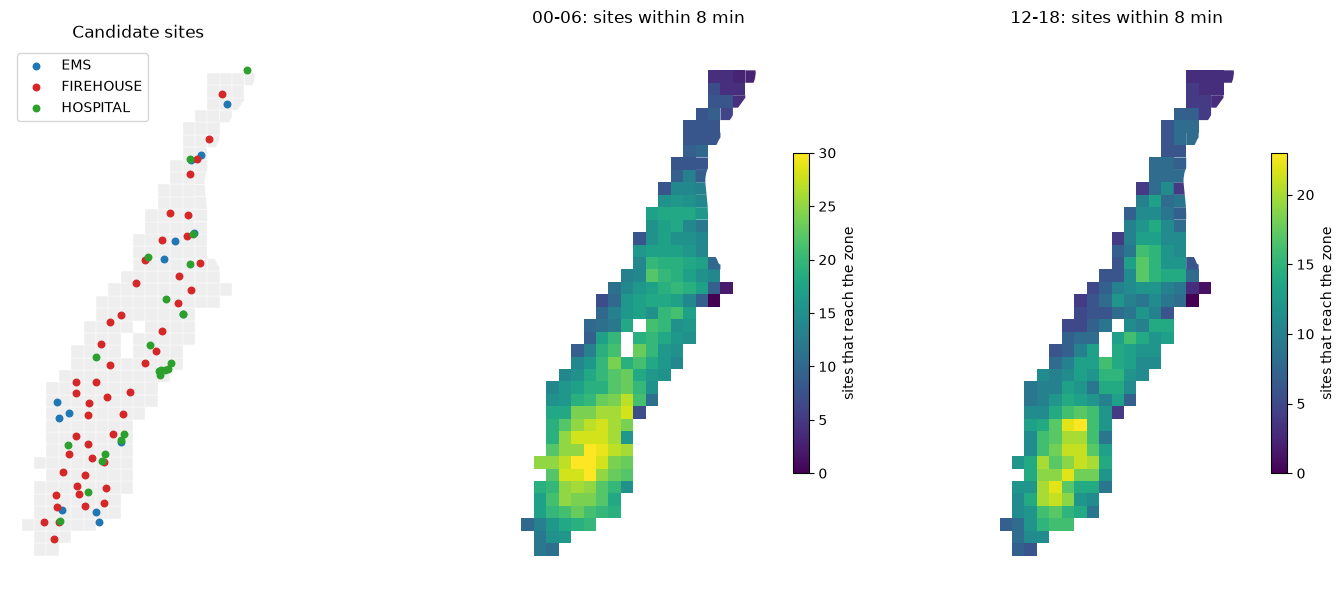

In [7]:
# travel time = congested distance / speed; a site "covers" a zone if that time is within the target
miles = (L + site_dist[:, None]) / 1609.344
tau = KAPPA[None, None, :] * miles[:, :, None] / SPEED_MPH * 60      # minutes, sites x zones x 4 periods
a = tau <= THETA_MIN

dv = d.values
covered_demand = 0
print("site-zone pairs that can cover:", int(a.sum()))
for t in range(4):
    covered = a[:, :, t].any(axis=0)
    covered_demand += dv[covered, t].sum()
    print(f"period {t}: pairs = {int(a[:, :, t].sum()):5d} | demand within reach of some site = {dv[covered, t].sum() / dv[:, t].sum():.3f}")
print("most coverage any plan could reach:", round(covered_demand / dv.sum(), 3))

np.save(ROOT / "a_ijt.npy", a)
np.save(ROOT / "L_metres.npy", L)
np.save(ROOT / "site_dist.npy", site_dist)

colors = {"EMS": "#1f77b4", "FIREHOUSE": "#d62728", "HOSPITAL": "#2ca02c"}
fig, ax = plt.subplots(1, 3, figsize=(15, 6))
zones.plot(ax=ax[0], color="#eeeeee", edgecolor="white", linewidth=0.3)
for typ, grp in sites.groupby("site_type"):
    ax[0].scatter(sp[grp.index].x, sp[grp.index].y, s=22, color=colors[typ], label=typ)
ax[0].legend(); ax[0].set_title("Candidate sites")
for k, t in enumerate([0, 2]):
    z = zones.assign(n=a[:, :, t].sum(axis=0))
    z.plot(ax=ax[k + 1], column="n", cmap="viridis", legend=True, legend_kwds={"label": "sites that reach the zone", "shrink": 0.6})
    ax[k + 1].set_title(["00-06", "06-12", "12-18", "18-24"][t] + ": sites within 8 min")
for x in ax: x.set_axis_off()
plt.tight_layout()
plt.show()

- 12,670 site-zone-period pairs can reach within 8 minutes. The model only uses the 11,420 of them where the zone actually has demand in that period.
- If every site were open with unlimited ambulances, 99.9% of crash demand is reachable, so the ceiling is basically 100%. The budget is what limits coverage, not geography.
- Daytime periods have fewer pairs than overnight (2,660 to 2,972 against 4,066) because traffic stretches the same trips.